# 03 · Baselines and model

In this notebook we decide how to judge a failure predictor and against what. We set the unit of evaluation
(the drive life), measure the rule a technician would use today, train LightGBM and compare it with each
version of the rule, which fixes the working threshold. We use only validation (Jul – Dec 2025); test stays
closed until notebook 04.

*Part 3 of 4 · Previous: [02 · Exploration and gold layer](02_exploration_and_gold_layer.ipynb) · Next: [04 · Results](04_results.ipynb)*

In [1]:
from backblaze_hdd_failure_prediction.figures import use_style
from backblaze_hdd_failure_prediction.notebooks import baselines_and_model as nb

use_style()
con = nb.connect()

## 1 · How to evaluate: per drive life, not per drive-day

The model scores every drive every day, so a healthy drive with stable "bad" values is flagged day after
day. The static rule flags about 30,000 drives on a single day; counted per drive-day, that adds up to some
5.5 million false alarms in six months. The technician acts once, on the first alert, so we count per **drive life**, with only the alerts
on days of the evaluated period (k = days to failure):

- **detected**: a failing life with an alert at k = 0 to 15; **with margin** if one alert has k ≥ 2
  (copying a 16–22 TB drive takes about a day);
- **false alarm**: a life that does not fail in the period, with an alert on a labelled day. Alerts to a
  failing drive more than 15 days ahead count as neither.

> **Decision**: count per drive life, only with the alerts of the evaluated period.
>
> **Why**: one alert is one piece of work, and failures are already counted per life.
>
> **Discarded**: counting false alarms per drive-day.

We load the validation period as the evaluation step left it and check that the rules and the model count
exactly the same lives. The table sorts the lives into failing ones, healthy ones with labelled days and healthy
ones without, and gives the median number of days of each label they have: the days on which an alert could
fall.

In [2]:
nb.load_validation(con)  # tables `period` (what each rule did, per life), `model_period` and `model_positive` (the model)
nb.show_validation_lives(con)

Lives counted differently by the rules and by the model: 0


,life,lives,median_days_label_0,median_days_label_1
0,"other, with labelled days",337528,184.0,0.0
1,fails in the period,1933,63.0,16.0
2,"other, without labelled days",94,0.0,0.0


**What we see**

- Validation has 339,555 lives: 1,933 fail in the period and 337,528 others have labelled days (94 have
  none). The rules and the model count exactly the same lives.
- A healthy life is watched on a median of 184 labelled days; a failing one can be caught on a median of 16.
  Per drive-day, one stubborn healthy drive would weigh like 184 errors.

## 2 · The baselines: the rule of five and random alerts

Without a model, a technician watches five S.M.A.R.T. attributes: 5 (reallocated sectors), 187 (reported
uncorrectable errors), 188 (command timeouts), 197 (current pending sectors) and 198 (offline uncorrectable
sectors). The **rule of five** alerts when one is above 0 (static rule) or rose over the last 7 or 30 days
(7-day and 30-day rules). The **random baseline** alerts on random drive-days, tuned to raise as many false
alarms as each rule: it is the floor.

> **Decision**: three versions of the rule, each with its random baseline.
>
> **Why**: the rule is today's practice; the 7-day rule raises fewer alarms but misses failures that come weeks
> after the rise, and having both costs almost nothing. Logistic regression and model + age baselines come in
> v3.

The output first counts the failures, and the silent ones that never showed any of the five attributes above 0.
The table then gives what each version of the rule achieves (failures detected, with margin, lead time and false
alarms) and what random alerts detect with the same number of false alarms.

In [3]:
references = nb.references(con)  # each rule, and random alerts with its false alarms (as in references.csv)
nb.show_references(references)

1,933 failures and 337,528 other lives (same as references.csv); 399 failures (20.6 %) never showed any of the five above 0


,detected,detected (%),with margin,median lead (days),false alarms,false alarms (% of other lives),random: detected
Static rule,"1,534",79.4,"1,422",15,"28,512",8.45,17
7-day rule,"1,281",66.3,"1,173",15,"13,377",3.96,4
30-day rule,"1,401",72.5,"1,276",15,"13,877",4.11,4


The figure compares the share of failures each rule detects with what random alerts detect at the same cost in
false alarms.

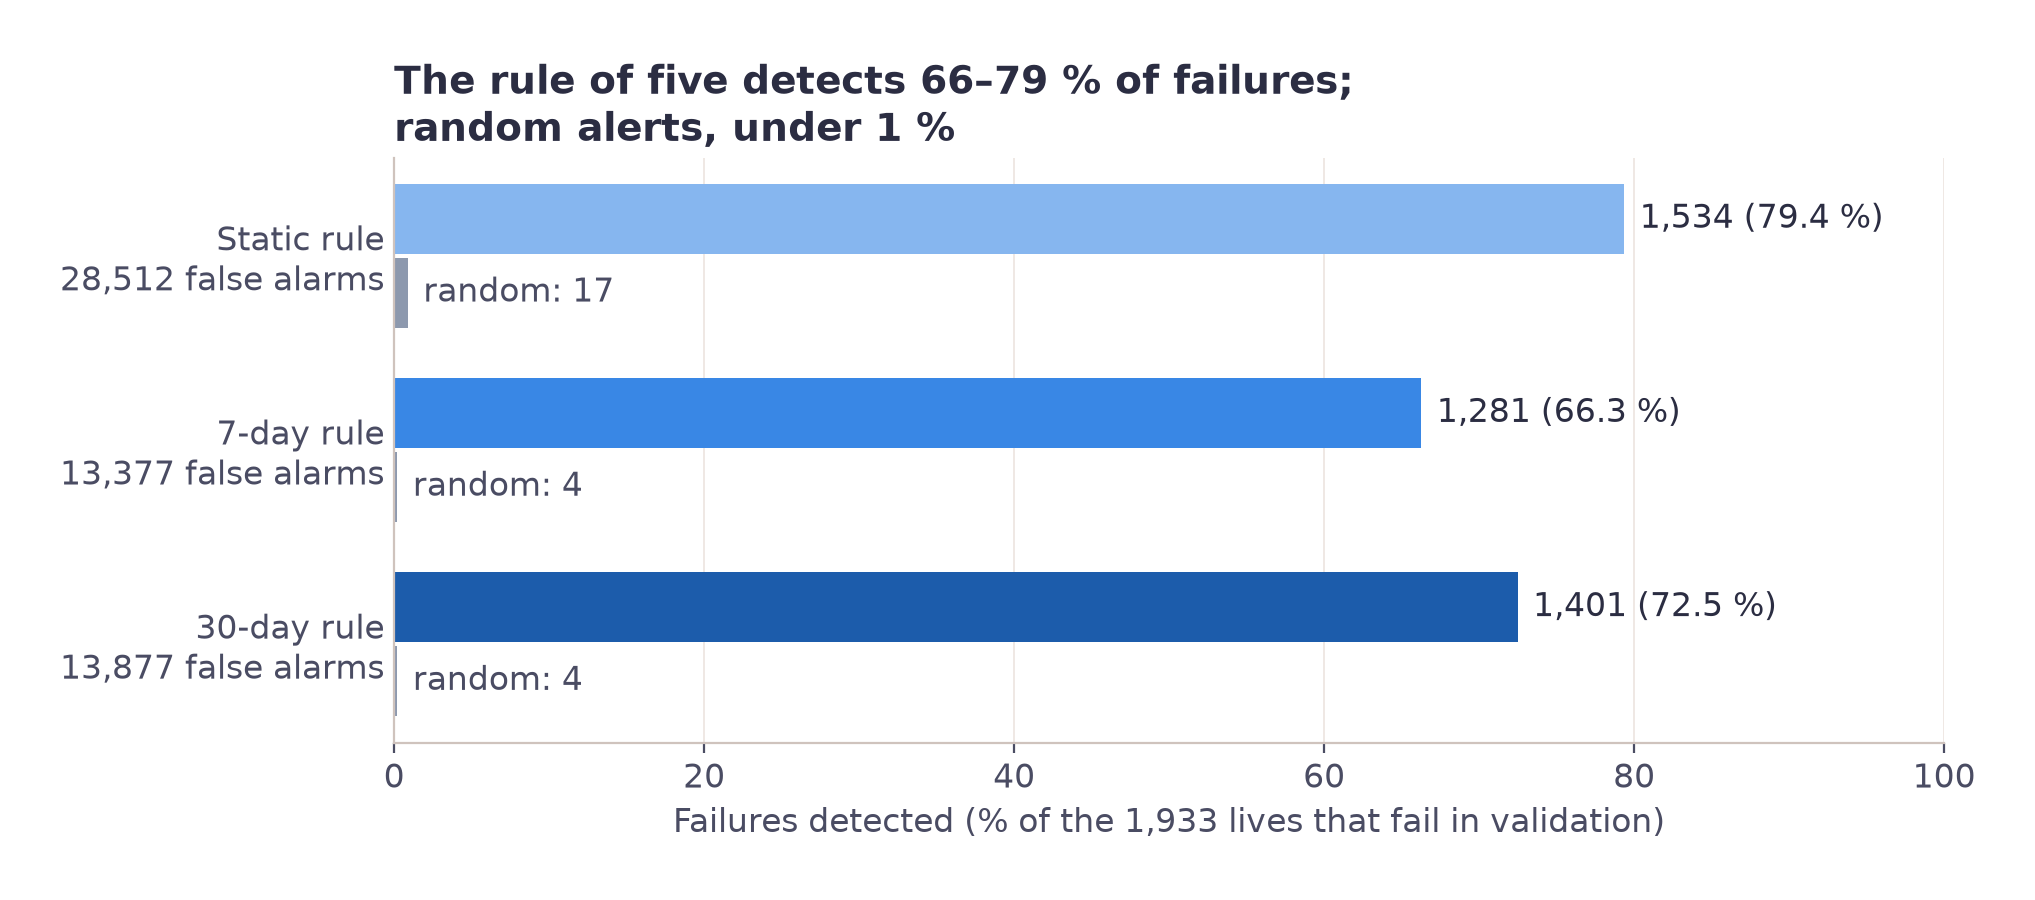

In [4]:
nb.plot_baselines(references)

**What we see**

- The static rule detects the most, 1,534 of 1,933 failures (79.4 %), but flags 28,512 of 337,528 other
  lives (8.45 %), twice as many as the dynamic rules.
- The 30-day rule detects 120 more failures than the 7-day rule for 500 more false alarms.
- Random alerts at the same cost detect 4 to 17 failures: a healthy life offers about 184 days to be hit,
  a failure only 16.
- 399 failures (20.6 %) never showed any of the five above 0: no rule can see them. The median lead time is
  15 days for every rule (the cap), so *with margin* says more.

## 3 · LightGBM: why, what it learns from, how it is tuned

LightGBM, a gradient-boosted tree model, scores each drive-day from the 131 variables of the gold layer
(notebook 02). Tuning: 10 combinations (reasonable values, then 9 at random with a fixed seed), each with
early stopping, ranked by PR-AUC on a validation sample.

> **Decision**: LightGBM as the working model.
>
> **Why**: tabular data, few positives, native missing values, explainable alerts, CPU only; tuned, about 1.7
> times faster than XGBoost and 4 times faster than CatBoost at similar quality (TabArena, NeurIPS 2025). The
> final choice comes in v3, against both, with the same tuning budget and bootstrap intervals.

> **Decision**: train on every positive drive-day and 0.5 % of the negatives, single days of the whole fleet
> picked by a fixed hash (reproducible).
>
> **Why**: the training period does not fit in memory, and a healthy drive's consecutive days are near copies: a
> few days of many drives teach more.

> **Decision**: drive models with fewer than 10 failures in training, or not seen in training, share one
> category, "otros" (others).
>
> **Why**: otherwise the model could learn "this drive model never fails" by chance.
>
> **Discarded**: duplicating rare failures (overfitting), moving validation data into training (leakage).

Before any result, the output describes what the model learnt from: its variables and its training sample,
compared with the whole training period and with validation. The ratio of positives to negatives in the sample
matters later, when we read the scores.

In [5]:
info = nb.model_info()
nb.show_training_sample(con, info)

131 variables, categorical: drive_model, manufacturer
Positives: 135,409 of 135,409 labelled 1 in training
Negatives: 1,036,843 of 207,300,364 labelled 0 in training (0.50 %)
1 positive per 7.7 negatives in the sample; 1 per 2,254 over every labelled drive-day of validation


The table shows how the drive model becomes a variable: drive models with at least 10 failures in training keep
their own category, and the rest share the "otros" category, grouped here by the reason.

In [6]:
nb.show_model_categories(con, info)

,drive_models,training_failures
category,,
otros: 1 to 9 failures in training,17,50
otros: no failure in training,17,0
otros: not in training,7,0
own category,33,8729


The search tried 10 combinations of settings. The output gives how far apart their PR-AUC is, and the table
lists them, best first.

In [7]:
nb.show_search(info)

PR-AUC on the validation sample: 0.7573 to 0.7620 (spread 0.0046); kept: combination 2, 405 trees


,learning_rate,num_leaves,min_data_in_leaf,feature_fraction,bagging_fraction,lambda_l2,trees,PR-AUC (sample)
combination,,,,,,,,
2,0.02,255,200,0.8,0.8,10.0,405,0.7620
6,0.10,127,200,1.0,0.8,1.0,73,0.7617
3,0.02,127,50,0.6,0.8,10.0,607,0.7614
9,0.10,63,50,1.0,0.8,10.0,155,0.7614
1,0.05,63,200,0.8,0.8,1.0,391,0.7608
7,0.05,31,50,0.8,1.0,0.0,441,0.7591
5,0.10,63,200,0.8,0.7,10.0,128,0.7589
8,0.10,255,50,0.8,0.7,10.0,71,0.7587
10,0.10,255,1000,0.6,0.8,1.0,66,0.7577


The figure shows the highest score the model gave each life, for the lives that fail and for the others. If the
model separates them, failing lives gather at high scores and healthy ones at low scores.

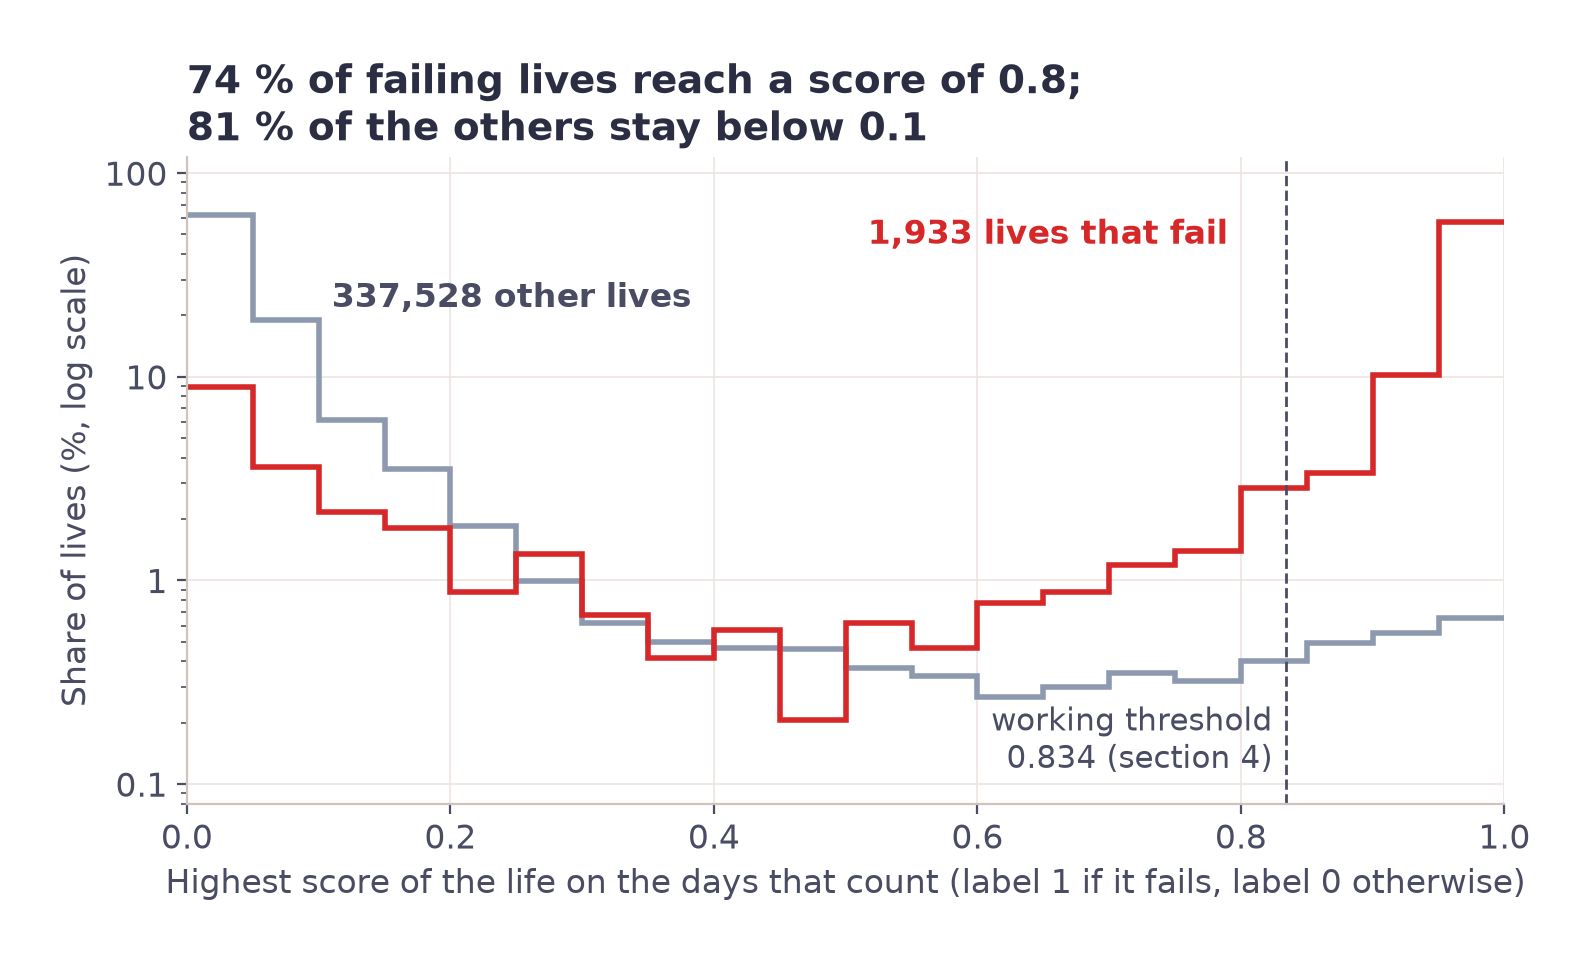

In [8]:
nb.plot_score_distribution(con)

**What we see**

- The sample has 1 positive per 7.7 negatives, against about 1 per 2,250 in validation, so scores are
  inflated: they rank drives but are not calibrated probabilities. Only the ranking matters here.
- 33 drive models keep their own category; 41 go to "otros".
- Tuning barely matters: the ten combinations span 0.757 to 0.762 (sample values, inflated too). The winner
  learns slowly (0.02) with large trees (255 leaves).
- 74 % of the failing lives reach 0.8 on some label-1 day; 81 % of the others never pass 0.1.

## 4 · Comparisons A and B, and the working threshold

A rule says yes or no; the model gives a ranking, and each threshold makes a different list. To compare two
watchmen fairly, we equal one thing and look at the other. Moving the threshold traces the **operating
curve**, failures detected against false alarms per life. **Comparison A** (the main one): same false alarms
as the rule, count failures detected. **Comparison B**: same failures detected, count false alarms.

The output traces the operating curve, what the model does at 44 thresholds from 0.15 to 0.995, and checks the
working threshold against the saved results. The table shows four points of the curve.

In [9]:
curve = nb.operating_curve(con)
nb.show_operating_curve(con, curve)

44 thresholds from 0.15 to 0.995; at the working threshold 0.8340: 1,401 detected, 1,238 with margin, 6,231 false alarms (as in lightgbm_v1.csv)


,threshold,detected,with_margin,median_lead_days,false_alarms
7,0.50,1534,1387,15.0,13693
24,0.90,1311,1135,14.0,4080
34,0.95,1114,939,12.0,2218
42,0.99,414,295,5.0,302


These are the two comparisons against each rule: A, the failures the model detects with the rule's false alarms,
and B, the false alarms it needs to detect the rule's failures. The lines before the table add, for B, the
failures detected with margin.

In [10]:
comparisons = nb.comparisons(con, references)  # A and B against each rule (as in lightgbm_v1.csv)
nb.show_comparisons(comparisons, references)

Static rule  with margin (k >= 2) in B: model 1,386, rule 1,422
7-day rule   with margin (k >= 2) in B: model 1,107, rule 1,173
30-day rule  with margin (k >= 2) in B: model 1,238, rule 1,276


The figure draws the model's operating curve with each rule and the random alerts, and marks comparisons A and B
against the 30-day rule and the working threshold.

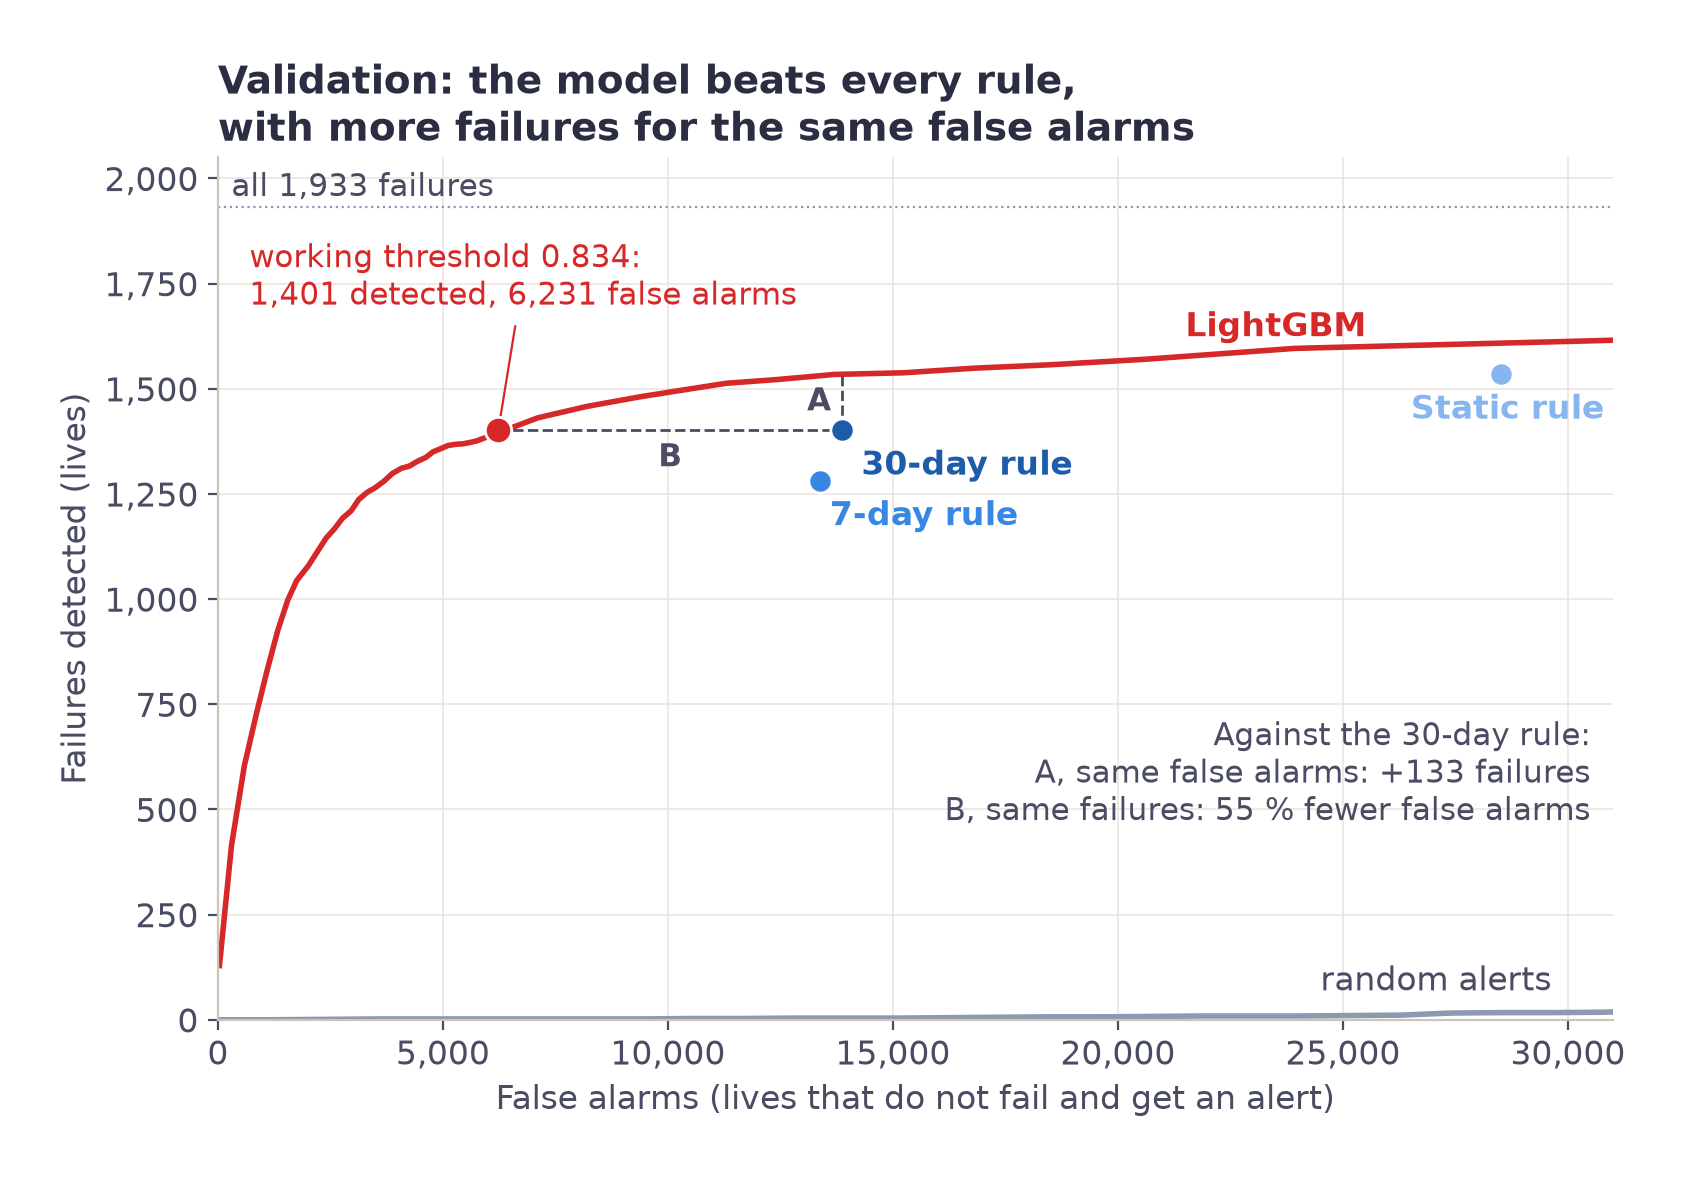

In [11]:
nb.plot_operating_curve(con, curve, references, comparisons)

**What we see**

- The curve lies above every rule. A: the model detects 1,608 against 1,534 (static), 1,530 against 1,281
  (7-day) and 1,534 against 1,401 (30-day).
- B: 52.1 % to 72.4 % fewer false alarms. The largest gain is against the 7-day rule, which misses rises
  that began weeks earlier; the smallest is A against the static rule (+74), where both catch almost
  everything that shows a signal.
- The price: in B, a little less margin (1,238 against 1,276 with k ≥ 2, against the 30-day rule), and near
  the top of the scale alerts come late (median lead time 12 days at 0.95, 5 at 0.99).

> **Decision**: working threshold 0.834 (B against the 30-day rule), for the technician's list, SHAP and the
> app.
>
> **Why**: the same 1,401 failures as the 30-day rule with 6,231 false alarms instead of 13,877: nothing gets
> worse and the list is less than half as long. A remains the main comparison of the results.
>
> **Discarded**: 0.49 (A against the 30-day rule; cost below) and 0.91 (B against the 7-day rule: fewer failures
> than the 30-day rule).

The output sets the working threshold next to comparison A against the same rule: what each list catches and
what it costs, and what going from one to the other would add. The last line gives the PR-AUC over every
labelled drive-day.

In [12]:
nb.show_working_threshold(con, comparisons, references)

working, B vs 30-day rule  threshold 0.8340: 1,401 detected (72.5 %), 6,231 false alarms; 1 in 5.4 lives on the list fails
A vs 30-day rule           threshold 0.4938: 1,534 detected (79.4 %), 13,877 false alarms; 1 in 10.0 lives on the list fails
From 0.834 down to 0.494: +133 failures for +7,646 false alarms (57 healthy lives per extra failure)


PR-AUC over every labelled drive-day: 0.118 (random alerts: 0.00044, the share of positive days)


**What we see**

- At 0.834 about 1 in 5 lives on the list (detected or false alarm) is a failure caught in time; at 0.49,
  1 in 10. Going down to 0.49 adds 133 failures for 7,646 false alarms: 57 healthy drives per extra failure.
- PR-AUC over every labelled drive-day: 0.118, against 0.00044 for random alerts (the share of positive days).
- Validation picked the combination, the stopping point and the threshold, so these numbers may be slightly
  optimistic; the test period, with this threshold fixed, gives the honest figure.

## Takeaways

- We count per drive life, with only the alerts of the period: an alert to a healthy drive is one false
  alarm, however long it lasts.
- The rule of five is a strong baseline (66.3 % to 79.4 % of failures detected; random alerts, 4 to 17), yet
  1 failure in 5 shows none of its five attributes.
- The model beats every rule both ways: more failures for the same false alarms (A), 52 % to 72 % fewer
  false alarms for the same failures (B). The working threshold, 0.834, keeps the 30-day rule's 1,401
  failures with 55 % fewer false alarms.

**Next, notebook 04:** this model and threshold, unchanged, on the test period (Jan – Jun 2026); why
detection drops there; what pushes each alert (SHAP); and the app.